# 03 · Modelos sobre todas las variantes de preprocesamiento

**Objetivo:** comparar varios clasificadores sobre **las seis variantes de preprocesamiento** del `02` (V0, V1, V2, V2 alarg.=1, V3, V4), sin descartar ninguna, y **guardar cada combinación como un modelo completo y reutilizable**.

Cada modelo es un único objeto de scikit-learn (`modeling.TweetToxicClassifier`) que recibe **texto crudo** y devuelve HS, TR y AG:

```
texto crudo
  → TweetPreprocessor(variante)          limpieza, minúsculas, ... (preprocessing.py)
  → ColumnTransformer de TF-IDF           palabras 1–2 + caracteres char_wb 2–5 (+ lemas en V4)
  → MultiOutputClassifier(clasificador)   un clasificador por etiqueta
  → umbral por etiqueta + jerarquía       si HS = 0, entonces TR = 0
```

**Conceptos que aparecen:**
- **Pipeline:** cadena de pasos de scikit-learn que se ajusta y se aplica como un solo objeto. Al guardarlo se guarda todo: preprocesamiento, vocabularios y clasificador.
- **Calibración:** la SVM lineal no da probabilidades, solo una puntuación. `CalibratedClassifierCV` la convierte en probabilidad ajustando una sigmoide con una validación interna.
- **Umbral elegido en los otros folds:** para el fold *k*, el umbral de cada etiqueta se elige con las predicciones OOF de los **otros 4 folds** y se aplica al fold *k*. Así el umbral nunca se elige mirando los datos que evalúa. Es una estimación mucho más honesta que optimizar el umbral sobre todas las OOF (como en el `02`).
- **joblib:** formato para guardar objetos de Python (el modelo entrenado) en disco y cargarlos después.

**Reglas que se respetan:** nada preentrenado (spaCy solo para lemas en V4, sin vectores); todo lo que se ajusta (diccionario de restauración, TF-IDF, clasificador, calibración) se ajusta **dentro de cada fold**; mismos folds (`data/processed/folds.csv`) y misma semilla para todas las combinaciones. Los hiperparámetros son los **valores por defecto** de cada clasificador: este notebook compara familias y variantes, no ajusta hiperparámetros.

## 1. Configuración y datos

In [1]:
import platform
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import spacy
from IPython.display import display

import modeling as md
import preprocessing as pp
from common import FIGURES_DIR, LABELS, PROCESSED_DIR, SEED, evaluate_oof, load_test, load_train, make_folds

np.random.seed(SEED)
sklearn.set_config(display="text")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
CLF_COLORS = {"logreg": "#2a78d6", "linsvm": "#eb6834", "cnb": "#1baf7a"}
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)


def savefig(fig, name):
    fig.savefig(FIGURES_DIR / f"03_{name}.png", dpi=120, bbox_inches="tight")


print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__} | spaCy {spacy.__version__} | SEED = {SEED}")

train = load_train()
test = load_test()
HAS_TEST = test is not None
Y = train[LABELS].to_numpy()
folds = make_folds(train)  # reutiliza data/processed/folds.csv
cache_file = PROCESSED_DIR / "lemma_cache.parquet"
if cache_file.exists():
    print(f"Caché de lemas precargada: {pp.load_lemma_cache(cache_file)} textos")
VARIANT_NAMES = list(pp.VARIANTS)
CLF_NAMES = list(md.CLASSIFIERS)
print(f"Train: {len(train)} | Test: {len(test) if HAS_TEST else '—'} | variantes: {VARIANT_NAMES} | clasificadores: {CLF_NAMES}")

Python 3.14.6 | scikit-learn 1.9.1 | spaCy 3.8.16 | SEED = 42
Caché de lemas precargada: 7014 textos
Train: 1731 | Test: 1154 | variantes: ['V0', 'V1', 'V2', 'V2 (alarg.=1)', 'V3', 'V4'] | clasificadores: ['logreg', 'linsvm', 'cnb']


## 2. El modelo completo

Así se ve un modelo (variante V4 con regresión logística) antes de entrenarlo. Los tres clasificadores comparados son:

| Clave | Clasificador | Por qué |
|---|---|---|
| `logreg` | Regresión logística, `class_weight="balanced"` | Es el modelo fijo del `02`: referencia directa |
| `linsvm` | SVM lineal (`LinearSVC`, balanceada) calibrada con sigmoide | Suele ser el mejor clasificador lineal sobre TF-IDF de texto |
| `cnb` | Complement Naive Bayes | Modelo probabilístico muy rápido, pensado para texto desbalanceado; aporta diversidad |

In [2]:
example = md.TweetToxicClassifier(variant="V4", classifier="logreg")
print(example)
print()
print(md.build_pipeline("V4", "logreg"))

TweetToxicClassifier(variant='V4')

Pipeline(steps=[('prep', TweetPreprocessor(variant='V4')),
                ('features',
                 ColumnTransformer(transformers=[('word',
                                                  TfidfVectorizer(lowercase=False,
                                                                  ngram_range=(1,
                                                                               2),
                                                                  sublinear_tf=True,
                                                                  token_pattern='(?u)<\\w+>|\\b\\w+\\b'),
                                                  'text'),
                                                 ('char',
                                                  TfidfVectorizer(analyzer='char_wb',
                                                                  lowercase=False,
                                                                  min_df=2,
                 

## 3. Validación cruzada: 6 variantes × 3 clasificadores

Para cada una de las 18 combinaciones se ejecuta la misma validación cruzada de 5 folds. En cada fold se clona el modelo y se ajusta **entero** (preprocesamiento, TF-IDF y clasificador) solo con los 4 folds de entrenamiento. Se reportan dos cifras:

- **F1 con umbral 0.5, sin jerarquía:** la salida "en bruto" del clasificador. Es comparable con el `02`.
- **F1 ajustado:** umbral por etiqueta elegido en los otros folds, más la regla de jerarquía (HS=0 ⇒ TR=0). Es la estimación del rendimiento del **modelo tal como se guarda**.

En ambos casos damos la media ± desviación entre los 5 folds.

In [3]:
cv = {}
for v in VARIANT_NAMES:
    for c in CLF_NAMES:
        cv[(v, c)] = md.cross_validate(md.TweetToxicClassifier(variant=v, classifier=c), train["text"], Y, folds)

METRICS = ["F1_HS", "F1_TR", "F1_AG", "F1_macro", "F1_micro"]
fmt = lambda s: f"{s.mean():.3f} ± {s.std():.3f}"
rows = []
for (v, c), r in cv.items():
    rows.append({"variante": v, "clasificador": c, "macro (0.5)": fmt(r["at_05"]["F1_macro"]),
                 "macro ajustado": fmt(r["tuned"]["F1_macro"]), "micro ajustado": fmt(r["tuned"]["F1_micro"]),
                 **{f"{lab} ajustado": round(r["tuned"][f"F1_{lab}"].mean(), 3) for lab in LABELS},
                 "tiempo CV (s)": round(r["fit_seconds"], 1)})
cv_table = pd.DataFrame(rows).set_index(["variante", "clasificador"])
display(cv_table)
print(f"Tiempo total de la validación cruzada: {sum(r['fit_seconds'] for r in cv.values()):.0f} s")

macro (0.5) macro ajustado micro ajustado  HS ajustado  TR ajustado  AG ajustado  tiempo CV (s)
variante      clasificador                                                                                                   
V0            logreg        0.744 ± 0.020  0.750 ± 0.016  0.747 ± 0.015        0.747        0.776        0.727            1.2
              linsvm        0.757 ± 0.023  0.766 ± 0.008  0.764 ± 0.008        0.765        0.803        0.731            1.3
              cnb           0.520 ± 0.027  0.699 ± 0.033  0.699 ± 0.031        0.718        0.717        0.661            0.9
V1            logreg        0.764 ± 0.027  0.772 ± 0.018  0.769 ± 0.017        0.772        0.803        0.741            1.0
              linsvm        0.773 ± 0.027  0.776 ± 0.022  0.772 ± 0.021        0.769        0.816        0.742            1.5
              cnb           0.613 ± 0.031  0.727 ± 0.018  0.727 ± 0.016        0.737        0.740        0.704            0.8
V2            logreg        0.762 ± 0.029  0.768 ± 0.019  0.765 ± 0.018        0.772        0.802        0.730            1.1
              linsvm        0.771 ± 0.027  0.778 ± 0.020  0.774 ± 0.019        0.779        0.815        0.739            1.5
              cnb           0.612 ± 0.032  0.717 ± 0.024  0.718 ± 0.021        0.729        0.726        0.697            0.8
V2 (alarg.=1) logreg        0.762 ± 0.030  0.769 ± 0.021  0.766 ± 0.020        0.768        0.803        0.735            1.1
              linsvm        0.768 ± 0.029  0.778 ± 0.022  0.775 ± 0.021        0.776        0.815        0.744            1.5
              cnb           0.612 ± 0.031  0.715 ± 0.024  0.716 ± 0.022        0.729        0.721        0.696            0.8
V3            logreg        0.764 ± 0.028  0.774 ± 0.020  0.772 ± 0.020        0.780        0.804        0.739            1.2
              linsvm        0.774 ± 0.032  0.782 ± 0.016  0.778 ± 0.016        0.776        0.823        0.746            1.7
              cnb           0.614 ± 0.037  0.724 ± 0.027  0.724 ± 0.026        0.735        0.743        0.695            1.0
V4            logreg        0.768 ± 0.030  0.771 ± 0.017  0.768 ± 0.018        0.769        0.808        0.735            1.6
              linsvm        0.775 ± 0.030  0.781 ± 0.020  0.777 ± 0.021        0.773        0.819        0.750            1.9
              cnb           0.627 ± 0.042  0.721 ± 0.023  0.722 ± 0.020        0.741        0.729        0.693            1.1

Tiempo total de la validación cruzada: 22 s


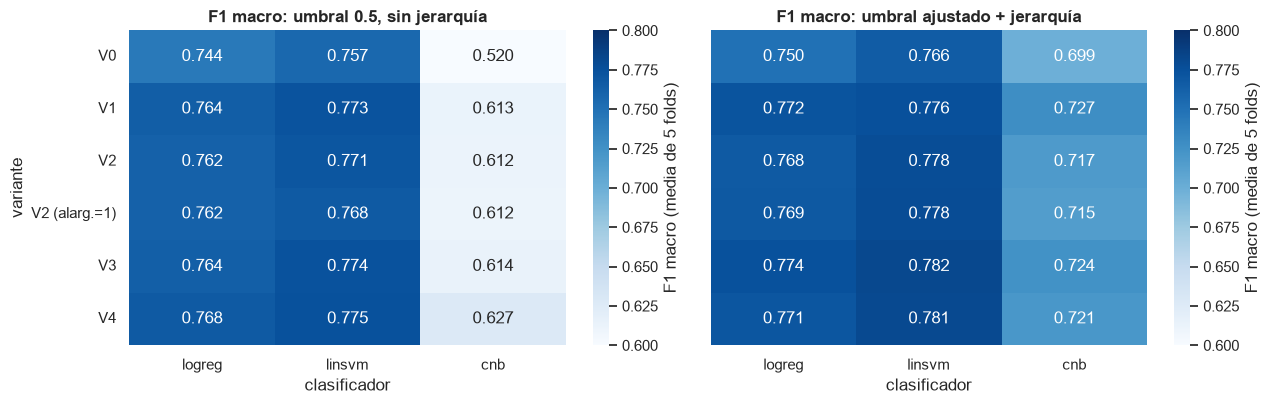

In [4]:
mean_tuned = pd.DataFrame({c: [cv[(v, c)]["tuned"]["F1_macro"].mean() for v in VARIANT_NAMES] for c in CLF_NAMES},
                          index=VARIANT_NAMES)
mean_05 = pd.DataFrame({c: [cv[(v, c)]["at_05"]["F1_macro"].mean() for v in VARIANT_NAMES] for c in CLF_NAMES},
                       index=VARIANT_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, (data, title) in zip(axes, [(mean_05, "umbral 0.5, sin jerarquía"), (mean_tuned, "umbral ajustado + jerarquía")]):
    sns.heatmap(data, annot=True, fmt=".3f", cmap="Blues", vmin=0.60, vmax=0.80, ax=ax,
                cbar_kws={"label": "F1 macro (media de 5 folds)"})
    ax.set(title=f"F1 macro: {title}", xlabel="clasificador", ylabel="variante" if ax is axes[0] else "")
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
savefig(fig, "f1_heatmap")
plt.show()

**Interpretación:**
- **La SVM lineal calibrada es el mejor clasificador en las seis variantes:** F1 macro ajustado de 0.766 a 0.782. La regresión logística va de 0.750 a 0.774 y Complement Naive Bayes de 0.699 a 0.727.
- **Complement NB con umbral 0.5 rinde muy mal** (0.520–0.627) porque sus probabilidades están muy descalibradas. Ajustando el umbral sube a 0.70–0.73, pero sigue claramente por detrás.
- **V0 (texto crudo) es la peor variante con los tres clasificadores.** Entre V1 y V4 las diferencias son pequeñas.
- **La mejor combinación es V3 + SVM lineal: 0.782 ± 0.016.** Con la regresión logística, la referencia del `02` (V1) pasa de 0.764 con umbral 0.5 a 0.772 ajustado.
- Por etiqueta se repite el patrón del `02`: TR es la más fácil (0.80–0.82 con la SVM) y AG la más difícil (0.73–0.75).

### ¿Qué diferencias son reales?

Como en el `02`, una diferencia solo cuenta si es **consistente entre folds**: la tomamos como real si la diferencia pareada media con la mejor combinación supera su propia desviación. Las combinaciones que no cumplen eso están **empatadas con la mejor**. Comparamos con el F1 ajustado, que es el del modelo que se guarda.

In [5]:
tuned_macro = {k: r["tuned"]["F1_macro"] for k, r in cv.items()}
best = max(tuned_macro, key=lambda k: tuned_macro[k].mean())
rows = []
for k, s in tuned_macro.items():
    d = tuned_macro[best] - s
    rows.append({"variante": k[0], "clasificador": k[1], "macro ajustado": s.mean(), "desv. folds": s.std(),
                 "Δ mejor − esta": d.mean(), "Δ desv.": d.std(),
                 "¿empatada con la mejor?": bool(k == best or d.mean() <= d.std())})
ranking = pd.DataFrame(rows).sort_values("macro ajustado", ascending=False).set_index(["variante", "clasificador"]).round(4)
display(ranking)
print(f"Mejor combinación: {best} | empatadas con ella: {int(ranking['¿empatada con la mejor?'].sum())} de {len(ranking)}")

,,macro ajustado,desv. folds,Δ mejor − esta,Δ desv.,¿empatada con la mejor?
variante,clasificador,,,,,
V3,linsvm,0.7817,0.0160,0.0000,0.0000,True
V4,linsvm,0.7807,0.0202,0.0010,0.0072,True
V2 (alarg.=1),linsvm,0.7782,0.0222,0.0035,0.0071,True
V2,linsvm,0.7776,0.0199,0.0041,0.0051,True
V1,linsvm,0.7756,0.0223,0.0061,0.0115,True
V3,logreg,0.7744,0.0196,0.0073,0.0064,False
V1,logreg,0.7720,0.0178,0.0097,0.0053,False
V4,logreg,0.7709,0.0174,0.0108,0.0056,False
V2 (alarg.=1),logreg,0.7687,0.0208,0.0130,0.0076,False


Mejor combinación: ('V3', 'linsvm') | empatadas con ella: 5 de 18


,media sobre variantes,peor variante,mejor variante
logreg,0.7673,0.7498,0.7744
linsvm,0.7767,0.7663,0.7817
cnb,0.7174,0.6989,0.7274


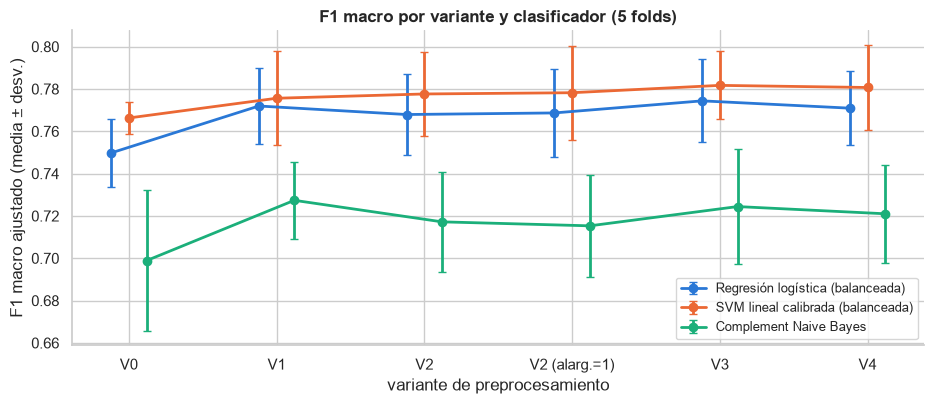

In [6]:
# Efecto del clasificador: su F1 macro ajustado medio, peor y mejor sobre las 6 variantes
by_clf = pd.DataFrame({c: [cv[(v, c)]["tuned"]["F1_macro"].mean() for v in VARIANT_NAMES] for c in CLF_NAMES}, index=VARIANT_NAMES)
summary_clf = by_clf.agg(["mean", "min", "max"]).T.round(4)
summary_clf.columns = ["media sobre variantes", "peor variante", "mejor variante"]
display(summary_clf)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(len(VARIANT_NAMES))
for i, c in enumerate(CLF_NAMES):
    means = [cv[(v, c)]["tuned"]["F1_macro"].mean() for v in VARIANT_NAMES]
    stds = [cv[(v, c)]["tuned"]["F1_macro"].std() for v in VARIANT_NAMES]
    ax.errorbar(x + (i - 1) * 0.12, means, yerr=stds, fmt="o-", color=CLF_COLORS[c], capsize=3, lw=2, ms=6,
                label=md.CLASSIFIER_NAMES[c])
ax.set(xticks=x, xticklabels=VARIANT_NAMES, xlabel="variante de preprocesamiento",
       ylabel="F1 macro ajustado (media ± desv.)", title="F1 macro por variante y clasificador (5 folds)")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
savefig(fig, "f1_by_variant")
plt.show()

**Interpretación:**
- **5 de las 18 combinaciones están empatadas con la mejor, y son todas SVM lineal con V1, V2, V2 (alarg.=1), V3 y V4** (0.776–0.782).
- V0 + SVM queda fuera: está 0.015 por debajo, con una desviación de 0.009.
- La regresión logística con V3 queda justo fuera del empate (diferencia 0.0073 frente a una desviación de 0.0064). Es un caso límite.
- **El clasificador pesa más que la variante.** La media sobre variantes es 0.777 para la SVM, 0.767 para la regresión logística y 0.717 para NB, mientras que dentro de cada clasificador las variantes V1–V4 difieren como mucho 0.007 en la SVM y en la regresión logística, y 0.012 en NB.
- Esto confirma el `02` con más modelos: limpiar y pasar a minúsculas (V0 → V1) es lo que importa. Los pasos c–f no cambian el resultado más allá del ruido con ninguno de los tres clasificadores.

## 4. ¿Cuánto aportan el umbral y la jerarquía?

Separamos los dos ajustes de la decisión final, a partir de las mismas predicciones OOF de cada combinación:

1. **umbral 0.5, sin jerarquía** (salida en bruto);
2. **umbral ajustado** en los otros folds, sin jerarquía;
3. **umbral ajustado + jerarquía** (el modelo guardado).

In [7]:
def tuned_without_hierarchy(oof):
    out = []
    for k in sorted(folds.unique()):
        val = (folds == k).to_numpy()
        thr = md.best_thresholds(Y[~val], oof[~val])
        out.append(evaluate_oof(Y[val], md.apply_decision(oof[val], thr, hierarchy=False), 0.5)["F1_macro"])
    return pd.Series(out)


rows = []
for (v, c), r in cv.items():
    no_h = tuned_without_hierarchy(r["oof"])
    rows.append({"clasificador": c, "variante": v, "0.5": r["at_05"]["F1_macro"].mean(), "umbral": no_h.mean(),
                 "umbral + jerarquía": r["tuned"]["F1_macro"].mean(),
                 "Δ umbral": (no_h - r["at_05"]["F1_macro"]).mean(),
                 "Δ jerarquía": (r["tuned"]["F1_macro"] - no_h).mean(),
                 "folds en que la jerarquía mejora": int((r["tuned"]["F1_macro"] > no_h).sum())})
effects = pd.DataFrame(rows)
display(effects.groupby("clasificador")[["0.5", "umbral", "umbral + jerarquía", "Δ umbral", "Δ jerarquía"]].mean().round(4))
print("Δ jerarquía por combinación (min / media / max):",
      np.round([effects["Δ jerarquía"].min(), effects["Δ jerarquía"].mean(), effects["Δ jerarquía"].max()], 4))

,0.5,umbral,umbral + jerarquía,Δ umbral,Δ jerarquía
clasificador,,,,,
cnb,0.5997,0.7160,0.7174,0.1163,0.0014
linsvm,0.7694,0.7770,0.7767,0.0076,-0.0003
logreg,0.7607,0.7637,0.7673,0.0029,0.0036


Δ jerarquía por combinación (min / media / max): [-0.0016  0.0016  0.0048]


**Interpretación:**
- **El umbral ajustado ayuda en proporción a lo descalibrado que está el modelo:** +0.116 de F1 macro en NB, +0.008 en la SVM y +0.003 en la regresión logística (balanceada, ya bastante bien calibrada).
- **La jerarquía tiene un efecto mínimo:** +0.0016 de media, con un rango de −0.0016 a +0.0048 entre combinaciones, dentro del ruido. Se mantiene porque no cuesta nada y evita predicciones imposibles (TR=1 con HS=0).

## 5. Entrenamiento final y guardado de los 18 modelos

Cada combinación se reentrena con **todo el train**, con estos ajustes:

- **Umbrales:** el umbral de cada etiqueta es el que maximiza el F1 sobre **todas** sus predicciones OOF. Es la mejor estimación disponible para el modelo final; su F1 esperado es el "F1 ajustado" de la sección 3, no el F1 sobre las OOF.
- **Jerarquía:** activada (HS=0 ⇒ TR=0).
- **Tuits vacíos:** los tuits sin texto real (`#¿NOMBRE?`) se predicen 000.

Por cada modelo se guarda en `models/`:
- `<variante>__<clasificador>.joblib`: el modelo completo, que recibe texto crudo.
- `<variante>__<clasificador>.json`: metadatos legibles (variante y sus pasos, clasificador, umbrales, métricas de la CV, versiones de las librerías, semilla y commit de git).

Además se guardan:
- `models/registry.csv`: índice de todos los modelos con sus métricas.
- `models/oof_predictions.parquet`: probabilidades OOF de cada combinación, para analizar errores o combinar modelos sin reentrenar.
- `models/test_predictions.parquet`: probabilidades y etiquetas de cada modelo sobre el test.

In [8]:
md.MODELS_DIR.mkdir(parents=True, exist_ok=True)
registry, oof_frames, test_frames, final_models = [], [], [], {}
t0 = time.perf_counter()
for (v, c), r in cv.items():
    name = md.model_name(v, c)
    thresholds = md.best_thresholds(Y, r["oof"])
    model = md.TweetToxicClassifier(variant=v, classifier=c, thresholds=thresholds, hierarchy=True).fit(train["text"], Y)
    cv_summary = {split: {m: {"mean": float(r[split][m].mean()), "std": float(r[split][m].std())} for m in METRICS}
                  for split in ["at_05", "tuned"]}
    path = md.save_model(model, name, {"cv": cv_summary, "cv_folds_file": "data/processed/folds.csv",
                                       "n_train": len(train), "thresholds_source": "F1 máximo sobre todas las OOF de la CV"})
    final_models[name] = model
    registry.append({"modelo": name, "variante": v, "clasificador": c,
                     "macro ajustado (CV)": round(r["tuned"]["F1_macro"].mean(), 4),
                     "desv.": round(r["tuned"]["F1_macro"].std(), 4),
                     "micro ajustado (CV)": round(r["tuned"]["F1_micro"].mean(), 4),
                     **{f"umbral {lab}": thresholds[lab] for lab in LABELS},
                     "archivo": path.name, "MB": round(path.stat().st_size / 1e6, 2)})
    oof_frames.append(pd.DataFrame({"id": train["id"], "modelo": name, **{f"p_{lab}": r["oof"][:, j] for j, lab in enumerate(LABELS)}}))
    if HAS_TEST:
        proba, pred = model.predict_proba(test["text"]), model.predict(test["text"])
        test_frames.append(pd.DataFrame({"id": test["id"], "modelo": name,
                                         **{f"p_{lab}": proba[:, j] for j, lab in enumerate(LABELS)},
                                         **{lab: pred[:, j] for j, lab in enumerate(LABELS)}}))
print(f"18 modelos entrenados y guardados en {time.perf_counter() - t0:.0f} s")

registry = pd.DataFrame(registry).sort_values("macro ajustado (CV)", ascending=False)
registry.to_csv(md.MODELS_DIR / "registry.csv", index=False)
pd.concat(oof_frames).to_parquet(md.MODELS_DIR / "oof_predictions.parquet", index=False)
if HAS_TEST:
    pd.concat(test_frames).to_parquet(md.MODELS_DIR / "test_predictions.parquet", index=False)
display(registry.set_index("modelo"))
print(f"Tamaño total de models/: {sum(p.stat().st_size for p in md.MODELS_DIR.glob('*')) / 1e6:.1f} MB")

18 modelos entrenados y guardados en 13 s


,variante,clasificador,macro ajustado (CV),desv.,micro ajustado (CV),umbral HS,umbral TR,umbral AG,archivo,MB
modelo,,,,,,,,,,
V3__linsvm,V3,linsvm,0.7817,0.0160,0.7781,0.46,0.40,0.44,V3__linsvm.joblib,2.05
V4__linsvm,V4,linsvm,0.7807,0.0202,0.7771,0.37,0.38,0.39,V4__linsvm.joblib,2.87
V2-alarg1__linsvm,V2 (alarg.=1),linsvm,0.7782,0.0222,0.7750,0.43,0.42,0.40,V2-alarg1__linsvm.joblib,2.06
V2__linsvm,V2,linsvm,0.7776,0.0199,0.7742,0.43,0.40,0.40,V2__linsvm.joblib,2.07
V1__linsvm,V1,linsvm,0.7756,0.0223,0.7716,0.40,0.38,0.41,V1__linsvm.joblib,2.08
V3__logreg,V3,logreg,0.7744,0.0196,0.7721,0.46,0.47,0.45,V3__logreg.joblib,0.99
V1__logreg,V1,logreg,0.7720,0.0178,0.7692,0.45,0.47,0.45,V1__logreg.joblib,1.00
V4__logreg,V4,logreg,0.7709,0.0174,0.7678,0.47,0.47,0.44,V4__logreg.joblib,1.43
V2-alarg1__logreg,V2 (alarg.=1),logreg,0.7687,0.0208,0.7656,0.45,0.49,0.45,V2-alarg1__logreg.joblib,0.99


Tamaño total de models/: 42.1 MB


**Interpretación:** los 18 modelos se entrenan y guardan en menos de medio minuto y ocupan 42 MB en total.
- **Tamaño por modelo:** unos 1 MB con regresión logística, 2–3 MB con SVM y 3–4 MB con NB, que guarda conteos por clase de cada n-grama.
- **Umbrales elegidos:** 0.41–0.49 en la regresión logística, 0.35–0.46 en la SVM y 0.05–0.17 en NB. Casi todos quedan por debajo de 0.5: con umbral 0.5 los modelos son conservadores y pierden positivos.

## 6. Reutilizar un modelo guardado

Para usar un modelo en otro notebook o script basta con tener `notebooks/` en el `sys.path` (por `preprocessing.py` y `modeling.py`) y cargarlo:

```python
import sys; sys.path.append("notebooks")
import modeling as md
model = md.load_model("V1__logreg")          # models/V1__logreg.joblib
model.predict(["@usuario cállate perra"])    # array([[HS, TR, AG]])
model.predict_proba(textos)                  # probabilidades (n, 3)
```

Comprobamos que **los 18 modelos cargados desde disco predicen exactamente lo mismo** que los que están en memoria, y probamos un modelo con textos nuevos escritos a mano. Uno de ellos lleva tildes, para ver que el preprocesamiento las borra igual que en el train.

In [9]:
check_texts = test["text"] if HAS_TEST else train["text"]
same = {}
for name, m in final_models.items():
    loaded = md.load_model(name)
    same[name] = bool(np.array_equal(loaded.predict_proba(check_texts), m.predict_proba(check_texts))
                      and np.array_equal(loaded.predict(check_texts), m.predict(check_texts)))
print(f"Modelos cuyo resultado tras cargar es idéntico: {sum(same.values())} de {len(same)}")

demo_name = registry.iloc[0]["modelo"]
demo = md.load_model(demo_name)
new_texts = pd.Series([
    "@usuario cállate perra, nadie te pregunto",
    "Los inmigrantes vienen a quitarnos el trabajo y las ayudas",
    "Qué bonito día para ir a la playa con mis amigas jajaja",
    "#¿NOMBRE?",
])
proba = demo.predict_proba(new_texts)
pred = demo.predict(new_texts)
print(f"Modelo: {demo_name} | umbrales: {demo.thresholds}")
display(pd.DataFrame({"texto": new_texts,
                      **{f"P({lab})": proba[:, j].round(2) for j, lab in enumerate(LABELS)},
                      **{lab: pred[:, j] for j, lab in enumerate(LABELS)}}))

Modelos cuyo resultado tras cargar es idéntico: 18 de 18
Modelo: V3__linsvm | umbrales: {'HS': 0.46, 'TR': 0.4, 'AG': 0.44}


,texto,P(HS),P(TR),P(AG),HS,TR,AG
0,"@usuario cállate perra, nadie te pregunto",0.96,0.96,0.93,1,1,1
1,Los inmigrantes vienen a quitarnos el trabajo y las ayudas,0.81,0.03,0.56,1,0,1
2,Qué bonito día para ir a la playa con mis amigas jajaja,0.40,0.19,0.26,0,0,0
3,#¿NOMBRE?,0.33,0.16,0.24,0,0,0


**Interpretación:** los **18 modelos cargados desde disco dan exactamente las mismas probabilidades y etiquetas** que los de memoria: el preprocesamiento, los vocabularios, los clasificadores y los umbrales viajan dentro del archivo.

Con el mejor modelo (V3 + SVM):
- *"@usuario cállate perra..."* sale 111, con probabilidades de ≈0.96. La tilde de *cállate* se borra igual que en el train.
- La frase contra inmigrantes sale HS=1, TR=0 y AG=1: odio contra un grupo, no contra una persona.
- La frase neutra sale 000.
- `#¿NOMBRE?` sale 000 por la regla de tuits vacíos, aunque su probabilidad no es cero.

In [10]:
if HAS_TEST:
    oof_all = pd.read_parquet(md.MODELS_DIR / "oof_predictions.parquet")
    test_all = pd.read_parquet(md.MODELS_DIR / "test_predictions.parquet")
    rows = []
    for name, model in final_models.items():
        oof_pred = md.apply_decision(oof_all.loc[oof_all["modelo"] == name, [f"p_{l}" for l in LABELS]].to_numpy(),
                                     model.thresholds, hierarchy=True)
        rows.append({"modelo": name,
                     **{f"{lab} test %": 100 * test_all.loc[test_all["modelo"] == name, lab].mean() for lab in LABELS},
                     **{f"{lab} OOF %": 100 * oof_pred[:, j].mean() for j, lab in enumerate(LABELS)}})
    rates = pd.DataFrame(rows).set_index("modelo").round(1)
    display(rates.loc[registry["modelo"]])
    print("Tasa real en train (%):", (100 * train[LABELS].mean()).round(1).to_dict())

,HS test %,TR test %,AG test %,HS OOF %,TR OOF %,AG OOF %
modelo,,,,,,
V3__linsvm,40.5,28.3,35.7,43.0,28.7,36.5
V4__linsvm,47.2,30.2,39.7,50.4,30.3,40.3
V2-alarg1__linsvm,41.9,28.2,38.2,45.1,28.9,39.3
V2__linsvm,42.4,28.9,38.1,45.1,29.2,39.4
V1__linsvm,45.1,29.7,37.4,47.7,30.1,38.9
V3__logreg,41.0,28.8,37.3,43.7,29.3,39.0
V1__logreg,41.9,28.9,37.6,45.5,30.0,39.3
V4__logreg,39.8,28.2,38.0,42.2,28.8,39.1
V2-alarg1__logreg,42.2,28.4,37.5,45.5,29.3,39.3


Tasa real en train (%): {'HS': 43.7, 'TR': 30.0, 'AG': 38.2}


**Interpretación:** la proporción de positivos que predice cada modelo en el test sigue a la de sus predicciones OOF en el train, y ambas están cerca de las tasas reales (HS 43.7%, TR 30.0%, AG 38.2%).
- El mejor modelo (V3 + SVM) predice 40.5% / 28.3% / 35.7% en test, frente a 43.0% / 28.7% / 36.5% en OOF.
- En HS, todos los modelos predicen entre 2.4 y 5.2 puntos menos de positivos en el test que en las OOF. Puede ser variación de muestreo (con 1154 tuits, el error estándar de una proporción es de ≈1.5 puntos) o un test con algo menos de odio. No es preocupante, porque la validación adversarial del EDA dio AUC 0.50.
- NB predice pocos TR (22–25%), lo que encaja con su F1 más bajo en esa etiqueta.

## 7. Conclusiones

| Pregunta | Respuesta (F1 macro ajustado, 5 folds) |
|---|---|
| ¿Mejor clasificador? | **SVM lineal calibrada**: es la mejor en las 6 variantes (media 0.777). Regresión logística 0.767; Complement NB 0.717, que no compite |
| ¿Mejor combinación? | **V3 + SVM** (0.782 ± 0.016), **empatada** dentro del ruido con SVM + V1, V2, V2 (alarg.=1) y V4 (0.776–0.781) |
| ¿Importa la variante? | Solo V0 frente al resto: V0 es la peor con los tres clasificadores. V1–V4 difieren como mucho 0.007 en la SVM y en la regresión logística |
| ¿Umbral? | Imprescindible en modelos descalibrados (NB +0.116); pequeño en la SVM (+0.008) y en la regresión logística (+0.003) |
| ¿Jerarquía? | Efecto nulo (+0.0016 de media), pero coherente y sin coste: se mantiene en los modelos guardados |
| ¿Reproducibilidad? | 18 modelos en `models/` que reciben texto crudo; idénticos tras guardarlos y cargarlos |

**Todas las variantes se conservan:** hay un modelo guardado por cada combinación, junto con sus predicciones OOF y de test.

**Siguientes pasos sugeridos:**
1. **Ajustar hiperparámetros** (sobre todo `C` de la SVM y de la regresión logística, y los rangos de n-gramas) solo en las familias competitivas, con validación cruzada anidada o reservando los umbrales para un paso interno.
2. **Combinar modelos** (media de probabilidades de varias variantes o clasificadores) usando `models/oof_predictions.parquet`, sin reentrenar.
3. Resolver **P1** (F1 macro o micro), que decide qué métrica optimizar, y **P2/P3** (artefacto de AG).
4. Definir el formato de envío a Kaggle a partir de `models/test_predictions.parquet`.

**Límites:**
- Hiperparámetros por defecto: la comparación es entre familias, no entre sus mejores versiones.
- El umbral elegido en los otros folds es una estimación *casi* honesta: las predicciones OOF de esos folds vienen de modelos que sí vieron el fold evaluado.
- Con 1731 tuits, la desviación entre folds es de ≈0.02. Diferencias menores no son significativas.
- Las etiquetas de AG siguen teniendo el artefacto H3.
- Los modelos ocupan 42 MB. Conviene decidir si se versionan en git o se regeneran ejecutando este notebook.